# KAN–PIN Framework: 1-D Burgers — Sawtooth Benchmark

**PDE:**
$$\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} = \nu\,\frac{\partial^2 u}{\partial x^2}, \quad x\in[0,2\pi],\; t\in[0,T]$$

**Analytic solution (Hopf–Cole transform):** sawtooth wave converging to a shock.  
**Reference method:** explicit FD upwind–advection + central–diffusion, periodic BC.  
**Goal:** train a KAN at each TD-PIN step, compare errors, conservation, and energy
dissipation, then inspect the learned activation functions.


In [1]:
import sys, os, time, copy
sys.path.insert(0, os.path.dirname(os.getcwd()))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from pinns_framework import (
    PINArchitecture, PINSpatialDimension, PINLossFunction, PINTrainer,
    save_pinns, load_pinns,
    collocation_curvature,
)

torch.manual_seed(0)
np.random.seed(0)
print('torch:', torch.__version__)


torch: 2.10.0


## 1. Problem Setup — Sawtooth Analytic Solution

The Hopf–Cole solution on $[0,2\pi]$ is:
$$u(t,x) = 2\nu\,\frac{\partial_x \ln\phi}{\phi} + 4, \qquad
\phi = e^{-a} + e^{-b}$$
with $a = \dfrac{(x-4t)^2}{4\nu(t+1)}$ and $b = \dfrac{(x-4t-2\pi)^2}{4\nu(t+1)}$.

This describes a sawtooth wave that sharpens into a viscous shock near $x=4t+\pi$ for large $t$.
With $\nu=0.07$ the shock is well-resolved throughout $T=0.01$.

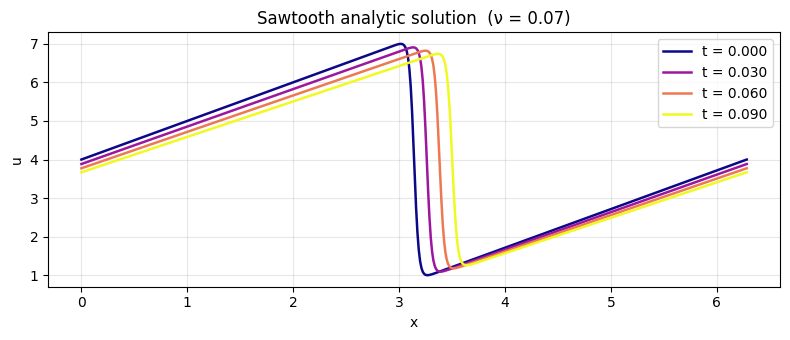

In [2]:
NU   = 0.07
X0, XF = 0.0, 2 * np.pi
T_END  = 0.03
DT     = 0.001
NT     = int(T_END / DT)   # 10 PDE steps

def toothsaw(t, x):
    """Hopf-Cole analytic solution for viscous Burgers on [0, 2π]."""
    x  = np.asarray(x, dtype=float)
    nu = NU
    c  = 4 * nu * (t + 1)
    a  = (-4*t + x)**2           / c
    b  = (-4*t + x - 2*np.pi)**2 / c
    num = ((-8*t + 2*x)             * np.exp(-a)
         + (-8*t + 2*x - 4*np.pi)  * np.exp(-b)) / c
    den = np.exp(-b) + np.exp(-a)
    return 2 * nu * num / den + 4

# ── Plot IC and selected snapshots ───────────────────────────────────────
x_plot = np.linspace(X0, XF, 500)
times_show = [0.0, 0.03, 0.06, 0.09]

fig, ax = plt.subplots(figsize=(8, 3.5))
cmap = plt.cm.plasma
for i, t in enumerate(times_show):
    ax.plot(x_plot, toothsaw(t, x_plot),
            color=cmap(i / max(len(times_show)-1, 1)),
            lw=1.8, label=f't = {t:.3f}')
ax.set_xlabel('x'); ax.set_ylabel('u')
ax.set_title('Sawtooth analytic solution  (ν = 0.07)')
ax.legend(loc='upper right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 2. Finite Difference Reference

**Scheme** (Barba et al. — explicit upwind advection + central diffusion, periodic BC):
$$u_i^{n+1} = u_i^n
  - u_i^n \frac{\Delta t}{\Delta x}\left(u_i^n - u_{i-1}^n\right)
  + \nu \frac{\Delta t}{\Delta x^2}\left(u_{i+1}^n - 2u_i^n + u_{i-1}^n\right)$$

Stability: $\text{CFL} = |u|_{\max}\,\Delta t/\Delta x \le 1$,  $r = \nu\,\Delta t/\Delta x^2 \le 0.5$.

FD is evaluated on the same dense grid used later for KAN error analysis.

In [3]:
# ── Evaluation grid (shared by FD and KAN error analysis) ────────────────
N_EVAL = 201
x_cmp  = np.linspace(X0, XF, N_EVAL)
dx_cmp = x_cmp[1] - x_cmp[0]

def fd_step(u, dx, dt, nu):
    """One explicit FD step with periodic boundary conditions."""
    u_prev = np.roll(u,  1)   # u_{i-1}
    u_next = np.roll(u, -1)   # u_{i+1}
    adv  = u * (u - u_prev) / dx
    diff = nu * (u_next - 2*u + u_prev) / dx**2
    return u - dt * adv + dt * diff

def fd_stability(u0, dx, dt, nu):
    CFL = float(np.max(np.abs(u0))) * dt / dx
    r   = nu * dt / dx**2
    print(f'  dx = {dx:.6f}   dt = {dt}')
    print(f'  CFL = {CFL:.4f}   (limit 1.0)   {'OK' if CFL < 1 else 'VIOLATED'}')
    print(f'  r   = {r:.4f}   (limit 0.5)   {'OK' if r < 0.5 else 'VIOLATED'}')

u0_fd = toothsaw(0, x_cmp)
print('=== FD Stability Report ===')
fd_stability(u0_fd, dx_cmp, DT, NU)


=== FD Stability Report ===
  dx = 0.031416   dt = 0.001
  CFL = 0.2226   (limit 1.0)   OK
  r   = 0.0709   (limit 0.5)   OK


In [4]:
# ── Run FD for all NT steps and store at each step ───────────────────────
times = [k * DT for k in range(NT + 1)]

t_fd_start = time.perf_counter()
fd_sols = {0.0: u0_fd.copy()}
u_fd = u0_fd.copy()
for k in range(1, NT + 1):
    u_fd = fd_step(u_fd, dx_cmp, DT, NU)
    fd_sols[times[k]] = u_fd.copy()
t_fd = time.perf_counter() - t_fd_start

print(f'FD wall time: {t_fd*1e3:.3f} ms  ({NT} steps)')


FD wall time: 1.784 ms  (30 steps)


## 3. KAN Setup

Architecture: `(1, 8, 1)` — 1 spatial input, 8 hidden neurons, 1 output.  
This gives **16 learnable activation functions** (8 input→hidden + 8 hidden→output),
small enough to visualize every edge but expressive enough to capture the sawtooth.

Collocation: `collocation_curvature` — concentrates 50 % of points where
$\sum_d |\partial^2 u / \partial x^2|$ is largest, helping resolve the sharper regions.

In [5]:
N_COLLOC = 150

net = PINArchitecture(
    arch='KAN',
    params_arch={'layers': (1, 16, 16, 1), 'grid_size': 5, 'spline_order': 4},
)
print(net)

x_dim = PINSpatialDimension('x', domain=(X0, XF), n_colloc=N_COLLOC)

def burgers_residual(u, u_prev, x, dt, nu):
    du_dx  = torch.autograd.grad(u.sum(),     x, create_graph=True)[0]
    du_dxx = torch.autograd.grad(du_dx.sum(), x, create_graph=True)[0]
    return (u - u_prev) / dt + u * du_dx - nu * du_dxx

loss_fn = PINLossFunction([x_dim], burgers_residual)

trainer = PINTrainer(
    net            = net,
    scheme         = 'TD-PINNS',
    loss_fn        = loss_fn,
    spatial_dims   = [x_dim],
    epochs         = 8000,
    dt             = DT,
    lr             = 1e-2,
    tolerance      = 1e-3,
    ic_weight      = 15.0,
    bc_weight      = 5.0,
    pde_weight     = 1.0,
    collocation_fn = collocation_curvature,
    verbose        = True,
    log_every      = 2000,
)
print(f'device: {trainer.device}')


checkpoint directory created: ./model
saving model version 0.0
KANNet(
  (net): MultKAN(
    (act_fun): ModuleList(
      (0-2): 3 x KANLayer(
        (base_fun): SiLU()
      )
    )
    (base_fun): SiLU()
    (symbolic_fun): ModuleList(
      (0-2): 3 x Symbolic_KANLayer()
    )
  )
)
device: mps


## 4. Initial and Boundary Conditions

**IC:** sampled from the exact solution at $t=0$.  
**BC:** $u(t, 0) \approx u(t, 2\pi) \approx 4$ throughout $T = 0.01$.  
This is verified analytically: the Hopf–Cole exponentials $e^{-b} \approx e^{-140} \approx 0$
make both boundary values indistinguishable from 4 for the entire simulation window.

IC range: [1.006, 6.994]
BC value: 4.000000  (exact at t=0)


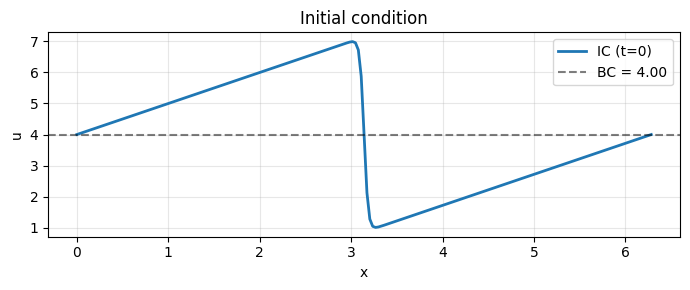

: 

In [ ]:
# IC on a fine grid
x_ic_np = np.linspace(X0, XF, 201)
u_ic_np = toothsaw(0, x_ic_np)

x_ic = torch.tensor(x_ic_np, dtype=torch.float32).unsqueeze(1)
u_ic = torch.tensor(u_ic_np, dtype=torch.float32).unsqueeze(1)

# BC: both endpoints ≈ 4 for T = 0.01
u_bc_val = float(toothsaw(0, X0))   # ≈ 4.0
x_bc = torch.tensor([[X0], [XF]])
u_bc = torch.full((2, 1), u_bc_val)

print(f'IC range: [{u_ic.min():.3f}, {u_ic.max():.3f}]')
print(f'BC value: {u_bc_val:.6f}  (exact at t=0)')

# Quick sanity plot
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(x_ic_np, u_ic_np, lw=2, label='IC (t=0)')
ax.axhline(u_bc_val, color='k', ls='--', alpha=0.5, label=f'BC = {u_bc_val:.2f}')
ax.set_xlabel('x'); ax.set_ylabel('u')
ax.set_title('Initial condition'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 5. Train

`trainer.fit` returns `list[nn.Module]` — one KAN per time level.
Index 0 = IC network (trained without PDE loss); indices 1…NT = PDE steps.

In [ ]:
t_kan_start = time.perf_counter()

trained_nets = trainer.fit(
    x_ic=x_ic, u_ic=u_ic,
    x_bc=x_bc, u_bc=u_bc,
    T=T_END,
    nu=NU,
)

t_kan = time.perf_counter() - t_kan_start
print(f'\nKAN wall time : {t_kan:.1f} s  ({len(trained_nets)-1} PDE steps)')
print(f'FD  wall time : {t_fd*1e3:.3f} ms')
print(f'Speed ratio   : {t_kan/t_fd:,.0f}× slower than FD')


=== TD-PINNs | step 0 — initial condition ===
  [step 0 / IC] converged at epoch 674 | loss 9.9719e-04
=== TD-PINNs | step 1/30  (t = 0.001) ===
  [step 1] epoch  2000 | loss 4.5749e+01
  [step 1] epoch  4000 | loss 1.2836e+01
  [step 1] epoch  6000 | loss 1.3705e+01
  [step 1] epoch  8000 | loss 1.1861e+01
=== TD-PINNs | step 2/30  (t = 0.002) ===
  [step 2] epoch  2000 | loss 2.5353e+01
  [step 2] epoch  4000 | loss 3.6470e+00
  [step 2] epoch  6000 | loss 2.8322e+00
  [step 2] epoch  8000 | loss 2.1894e+00
=== TD-PINNs | step 3/30  (t = 0.003) ===
  [step 3] epoch  2000 | loss 7.3098e+00
  [step 3] epoch  4000 | loss 2.6520e+00
  [step 3] epoch  6000 | loss 2.0528e+00
  [step 3] epoch  8000 | loss 2.3626e+00
=== TD-PINNs | step 4/30  (t = 0.004) ===
  [step 4] epoch  2000 | loss 2.8767e+01
  [step 4] epoch  4000 | loss 6.1864e+00
  [step 4] epoch  6000 | loss 4.6516e+00
  [step 4] epoch  8000 | loss 4.4375e+00
=== TD-PINNs | step 5/30  (t = 0.005) ===


2026-04-30 22:01:59.973 Python[13131:102592] Error creating directory 
 No queda espacio disponible en el volumen ‚ÄúMacintosh HD‚Äù. El archivo ‚Äúmpsgraph-13131-2026-04-30_22_01_59-2399711335‚Äù no puede guardarse porque no queda espacio en el volumen ‚ÄúMacintosh HD‚Äù.


## 6. Solution Comparison — KAN vs FD vs Exact

In [1]:
# ── Evaluate KAN on x_cmp ────────────────────────────────────────────────
dev = trainer.device
x_t = torch.tensor(x_cmp, dtype=torch.float32).unsqueeze(1).to(dev)

kan_sols = {}
for k, net_k in enumerate(trained_nets):
    t = times[k]
    net_k.eval()
    with torch.no_grad():
        kan_sols[t] = net_k(x_t).cpu().numpy().ravel()


NameError: name 'trainer' is not defined

In [ ]:
# ── Grid of subplots: one per time step ──────────────────────────────────
ncols = 4
nrows = (NT + 1 + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.2 * nrows))
axes = axes.flatten()

for k, t in enumerate(times):
    ax = axes[k]
    u_ex  = toothsaw(t, x_cmp)
    u_kan = kan_sols[t]
    u_fd  = fd_sols[t]

    ax.plot(x_cmp, u_ex,  'k-',   lw=1.5,  label='Exact')
    ax.plot(x_cmp, u_kan, 'b--',  lw=1.5,  label='KAN')
    ax.plot(x_cmp, u_fd,  'r:',   lw=1.5,  label='FD')
    ax.set_title(f't = {t:.3f}', fontsize=10)
    ax.set_xlabel('x'); ax.set_ylabel('u')
    ax.grid(alpha=0.25)
    if k == 0:
        ax.legend(fontsize=8)

for ax in axes[NT+1:]:
    ax.set_visible(False)

fig.suptitle('KAN vs FD vs Exact — all time steps', fontsize=13)
plt.tight_layout(); plt.show()


## 7. Error Analysis — L1, L2, L∞

Errors are computed on the dense uniform grid `x_cmp` (N=201 points)
using the trapezoidal rule for integrated norms:
$$\|e\|_1 = \int|u-u^\star|dx, \quad
\|e\|_2 = \sqrt{\int|u-u^\star|^2 dx}, \quad
\|e\|_\infty = \max|u-u^\star|$$

In [ ]:
def error_row(u_pred, u_exact, x, label):
    diff  = np.abs(u_pred - u_exact)
    dx    = x[1] - x[0]
    L1    = np.trapz(diff,       x)
    L2    = np.sqrt(np.trapz(diff**2, x))
    Linf  = diff.max()
    rL2   = L2 / (np.sqrt(np.trapz(u_exact**2, x)) + 1e-12)
    mass  = np.trapz(u_pred,   x)
    energy= np.trapz(u_pred**2, x)
    return {f'{label}_L1':L1, f'{label}_L2':L2,
            f'{label}_Linf':Linf, f'{label}_rel_L2':rL2,
            f'{label}_mass':mass, f'{label}_energy':energy}

rows = []
for t in times:
    u_ex = toothsaw(t, x_cmp)
    row  = {'t': t}
    row.update(error_row(kan_sols[t], u_ex, x_cmp, 'KAN'))
    row.update(error_row(fd_sols[t],  u_ex, x_cmp, 'FD'))
    row['exact_mass']   = np.trapz(u_ex,    x_cmp)
    row['exact_energy'] = np.trapz(u_ex**2, x_cmp)
    rows.append(row)

df = pd.DataFrame(rows).set_index('t')

pd.set_option('display.float_format', '{:.6f}'.format)
print('=== Per-step errors ===')
print(df[['KAN_L1','FD_L1','KAN_L2','FD_L2','KAN_Linf','FD_Linf','KAN_rel_L2','FD_rel_L2']].to_string())

print('\n=== Summary ===')
summary = pd.DataFrame({
    'metric': ['mean L1','max L1','mean L2','max L2','mean Linf','max Linf',
               'mean rel_L2','mass max err','energy at T'],
    'KAN': [
        df['KAN_L1'].mean(),  df['KAN_L1'].max(),
        df['KAN_L2'].mean(),  df['KAN_L2'].max(),
        df['KAN_Linf'].mean(),df['KAN_Linf'].max(),
        df['KAN_rel_L2'].mean(),
        (df['KAN_mass'] - df['exact_mass']).abs().max(),
        df['KAN_energy'].iloc[-1],
    ],
    'FD': [
        df['FD_L1'].mean(),   df['FD_L1'].max(),
        df['FD_L2'].mean(),   df['FD_L2'].max(),
        df['FD_Linf'].mean(), df['FD_Linf'].max(),
        df['FD_rel_L2'].mean(),
        (df['FD_mass'] - df['exact_mass']).abs().max(),
        df['FD_energy'].iloc[-1],
    ],
}).set_index('metric')
print(summary.to_string())


In [ ]:
# ── Error evolution (semilogy) ────────────────────────────────────────────
t_plot = times[1:]   # skip t=0 (FD has 0 error there by construction)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)
metrics = [('L1', 'L₁'), ('L2', 'L₂'), ('Linf', 'L∞')]

for ax, (key, label) in zip(axes, metrics):
    ax.semilogy(t_plot, df.loc[t_plot, f'KAN_{key}'], 'b-o', lw=1.5, ms=5, label='KAN')
    ax.semilogy(t_plot, df.loc[t_plot, f'FD_{key}'],  'r--s', lw=1.5, ms=5, label='FD')
    ax.set_xlabel('t'); ax.set_ylabel(f'{label} error')
    ax.set_title(f'{label} error evolution')
    ax.legend(); ax.grid(True, which='both', alpha=0.3)

plt.suptitle('KAN vs FD — error evolution', fontsize=12)
plt.tight_layout(); plt.show()


## 8. Conservation & Energy Dissipation

**Mass** $M(t) = \int u\,dx$ should remain approximately constant (Burgers with periodic-like BC).  
**Energy** $E(t) = \int u^2\,dx$ dissipates due to viscosity:  
$$\frac{dE}{dt} = -2\nu\int\left(\frac{\partial u}{\partial x}\right)^2 dx \le 0$$

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Mass conservation
ax = axes[0]
ax.plot(times, df['exact_energy'] * 0 + df['exact_mass'],  # flat reference
        'k-',  lw=2,   label='Exact')
ax.plot(times, df['exact_mass'],  'k-',  lw=2)
ax.plot(times, df['KAN_mass'],    'b-o', lw=1.5, ms=5, label='KAN')
ax.plot(times, df['FD_mass'],     'r--s',lw=1.5, ms=5, label='FD')
ax.set_xlabel('t'); ax.set_ylabel('$\\int u\\,dx$')
ax.set_title('Mass conservation'); ax.legend(); ax.grid(alpha=0.3)

# Energy dissipation
ax = axes[1]
ax.plot(times, df['exact_energy'], 'k-',  lw=2,   label='Exact')
ax.plot(times, df['KAN_energy'],   'b-o', lw=1.5, ms=5, label='KAN')
ax.plot(times, df['FD_energy'],    'r--s',lw=1.5, ms=5, label='FD')
ax.set_xlabel('t'); ax.set_ylabel('$\\int u^2\\,dx$')
ax.set_title('Energy dissipation  ($dE/dt \\leq 0$)'); ax.legend(); ax.grid(alpha=0.3)

plt.suptitle('Conservation diagnostics', fontsize=12)
plt.tight_layout(); plt.show()

# Mass and energy error vs exact
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, key, title in [
    (axes[0], 'mass',   'Mass error  |M_pred - M_exact|'),
    (axes[1], 'energy', 'Energy error  |E_pred - E_exact|'),
]:
    ax.semilogy(times, (df[f'KAN_{key}'] - df['exact_mass' if key=='mass' else 'exact_energy']).abs(),
               'b-o', lw=1.5, ms=5, label='KAN')
    ax.semilogy(times, (df[f'FD_{key}']  - df['exact_mass' if key=='mass' else 'exact_energy']).abs(),
               'r--s', lw=1.5, ms=5, label='FD')
    ax.set_xlabel('t'); ax.set_title(title)
    ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()


## 9. KAN Graph Visualization

Each box on an edge of the graph shows the **learned spline activation function**
for that connection.  Edge thickness encodes importance (from `attribute()`).

`_kan_cpu` deep-copies the inner PyKAN model to CPU and re-runs a forward pass
before any pykan introspection call — this avoids MPS/CUDA device mismatches.

In [ ]:
def _kan_cpu(kan_net, x_1d):
    """
    Deep-copy the KANNet's inner PyKAN model to CPU and populate all
    activation caches.  Safe regardless of training device.
    """
    model = copy.deepcopy(kan_net.net).cpu()
    x_cpu = x_1d.detach().cpu().reshape(-1, 1)
    with torch.no_grad():
        model(x_cpu)
    model.get_act(x_cpu)
    return model, x_cpu


def plot_kan_step(trained_nets, step, x_domain, dt,
                  n_vis=300, prune=False, node_th=1e-2, edge_th=1e-2, beta=3):
    """Visualize the KAN at one TD-PIN time step."""
    lo, hi = x_domain
    x_vis  = torch.linspace(lo, hi, n_vis).unsqueeze(1)
    kan, x_cpu = _kan_cpu(trained_nets[step], x_vis)

    tag = ''
    if prune:
        try:
            kan = kan.prune(node_th=node_th, edge_th=edge_th)
            with torch.no_grad():
                kan(x_cpu)
            kan.get_act(x_cpu)
            tag = ' [pruned]'
        except Exception as exc:
            print(f'  step {step}: pruning skipped — {exc}')
            tag = ' [prune failed — unpruned]'

    kan.plot(beta=beta, in_vars=['x'], out_vars=['u'])
    plt.suptitle(f'KAN  step {step}   t = {step * dt:.3f}{tag}',
                 fontsize=11, y=1.02)
    plt.tight_layout()
    plt.show()
    return kan


In [ ]:
# ── KAN graph at IC and three PDE steps ──────────────────────────────────
x_dom = (X0, XF)
show  = [0, 1, NT // 2, NT]

for step in show:
    plot_kan_step(trained_nets, step, x_dom, DT, prune=False)


In [ ]:
# ── Pruned KAN graphs — see only the dominant pathways ───────────────────
for step in [1, NT]:
    plot_kan_step(trained_nets, step, x_dom, DT,
                  prune=True, node_th=1e-2, edge_th=1e-2)


## 10. KAN Activation Functions — Learned Modes

For a `(1, K, 1)` KAN there are two sets of activation functions:  
- **Layer 0** (input → hidden): $K$ functions $\varphi_{0,j}(x)$, each mapping
  the spatial coordinate $x$ to a feature for hidden neuron $j$.  
- **Layer 1** (hidden → output): $K$ functions $\varphi_{1,j}(h_j)$, each mapping
  the $j$-th hidden neuron's output to a contribution to $u$.

The final prediction is:
$$u(x) = \sum_{j=1}^{K} \varphi_{1,j}\!\left(\varphi_{0,j}(x)\right)$$

These learned functions are analogous to **modes** in a spectral expansion
but are adapted directly to the PDE solution — unlike Fourier modes, they
are not fixed.

In [ ]:
def plot_kan_modes(trained_nets, step, x_domain, dt, n_vis=400):
    """
    Plot all activation functions for every layer of a KAN of any depth.

    Layer 0      : K1 functions  φ_{0,j}(x)         — input features
    Layer 1..L-2 : Ki×K_{i+1} functions              — intermediate transforms
    Layer L-1    : K_{L-1} functions                 — output aggregators
    """
    lo, hi = x_domain
    x_vis  = torch.linspace(lo, hi, n_vis).unsqueeze(1)
    kan, x_cpu = _kan_cpu(trained_nets[step], x_vis)
    x_np = x_cpu.squeeze().numpy()

    try:
        posts = [p.detach().numpy() for p in kan.spline_postacts]
    except Exception as e:
        print(f'Cannot extract postacts: {e}'); return

    n_layers = len(posts)

    for l, post in enumerate(posts):
        # post shape: (N, n_out, n_in) for layer l
        n_out, n_in = post.shape[1], post.shape[2]
        n_edges = n_out * n_in
        cols = min(n_edges, 8)
        rows = (n_edges + cols - 1) // cols
        fig, axes = plt.subplots(rows, cols,
                                  figsize=(2.2 * cols, 2.8 * rows),
                                  squeeze=False)
        colors = plt.cm.tab10(np.linspace(0, 1, n_in))

        edge = 0
        for j in range(n_in):
            for k in range(n_out):
                ax = axes[edge // cols][edge % cols]
                # x-axis: input to this edge
                if l == 0:
                    h_in = x_np                               # layer 0 input = x
                elif kan.acts and len(kan.acts) > l:
                    h_in_t = kan.acts[l]
                    h_in = (h_in_t[:, j].detach().numpy()
                            if h_in_t.dim() > 1 else h_in_t.detach().numpy())
                else:
                    h_in = np.arange(len(post[:, k, j]))

                y_vals = post[:, k, j]
                idx    = np.argsort(h_in)
                ax.plot(h_in[idx], y_vals[idx], color=colors[j % 10], lw=1.4)

                in_label  = 'x' if l == 0 else f'$h_{{{l},{j+1}}}$'
                out_label = f'$h_{{{l+1},{k+1}}}$' if l < n_layers-1 else 'u'
                ax.set_title(f'$\\varphi_{{{l},{j+1}\\to {k+1}}}$  '
                             f'({in_label}→{out_label})', fontsize=8)
                ax.tick_params(labelsize=6)
                ax.grid(alpha=0.3)
                edge += 1

        for ax in axes.flatten()[edge:]:
            ax.set_visible(False)

        plt.suptitle(
            f'KAN layer {l} activation functions — '
            f'step {step}  (t = {step * dt:.3f})',
            fontsize=10)
        plt.tight_layout()
        plt.show()


# Show modes at IC, mid, and final step
for step in [0, NT // 2, NT]:
    plot_kan_modes(trained_nets, step, x_dom, DT)


### Mode evolution across time steps

Overlay the first-layer activations $\varphi_{0,j}(x)$ for all time steps
to see how each basis function adapts to the evolving solution.

In [ ]:
n_vis = 400
x_vis = torch.linspace(X0, XF, n_vis).unsqueeze(1)

# Collect postacts[0] for every step
all_post0 = {}   # step → (N, K) array
K = None
for step in range(len(trained_nets)):
    try:
        kan, x_cpu = _kan_cpu(trained_nets[step], x_vis)
        p0 = kan.spline_postacts[0].detach().numpy()  # (N, K, 1)
        all_post0[step] = p0[:, :, 0]                 # (N, K)
        K = p0.shape[1]
    except Exception:
        pass

if K is not None:
    x_np = x_vis.squeeze().numpy()
    fig, axes = plt.subplots(2, K // 2, figsize=(2.5 * K // 2, 5))
    axes = axes.flatten()
    cmap_t = plt.cm.viridis

    for j in range(K):
        ax = axes[j]
        for step, p0 in all_post0.items():
            ax.plot(x_np, p0[:, j],
                    color=cmap_t(step / max(len(trained_nets)-1, 1)),
                    lw=0.9, alpha=0.8)
        ax.set_title(f'$\\varphi_{{0,{j+1}}}$ across steps', fontsize=9)
        ax.tick_params(labelsize=7)
        ax.grid(alpha=0.25)

    # colorbar for time
    sm = plt.cm.ScalarMappable(cmap=cmap_t,
                                norm=plt.Normalize(vmin=0, vmax=T_END))
    fig.colorbar(sm, ax=axes, label='t', shrink=0.6)
    plt.suptitle('Layer-0 activation functions evolution (color = time)',
                 fontsize=11)
    plt.tight_layout()
    plt.show()


## 11. Symbolic Interpretation (`auto_symbolic`)

pykan can attempt to fit each learned spline to a symbolic formula from a
user-provided library.  This gives insight into what mathematical operations
the network has learned to represent the PDE solution.

> **Note:** `auto_symbolic` can take 1–2 minutes for all edges.

In [ ]:
SYMB_LIB = ['x', 'x^2', 'x^3', 'x^4', 'sin', 'cos', 'exp', 'log',
            'tanh', 'abs', 'sqrt']

def symbolic_summary(trained_nets, step, x_domain, dt, lib=SYMB_LIB):
    lo, hi = x_domain
    x_vis  = torch.linspace(lo, hi, 300).unsqueeze(1)
    kan, x_cpu = _kan_cpu(trained_nets[step], x_vis)

    try:
        kan.auto_symbolic(lib=lib)
        print(f'\n--- Step {step}  (t = {step * dt:.3f}) ---')
        kan.print_node_scores()
    except Exception as e:
        print(f'auto_symbolic failed at step {step}: {e}')
    return kan

# Run on the final step (richest dynamics)
kan_sym = symbolic_summary(trained_nets, NT, x_dom, DT)


## 12. KAN vs Finite Differences — Conceptual Comparison

| Aspect | FD (explicit upwind) | KAN (TD-PIN) |
|---|---|---|
| Representation | $u$ on fixed grid | $u(x)$ as continuous function |
| Discretization | $\Delta x$-error ($\mathcal{O}(\Delta x)$ in space) | none — mesh-free |
| Stencil | fixed 3-point local polynomial | learned adaptive splines |
| Nonlinearity | $u\,\Delta u / \Delta x$ — fixed form | learned implicitly |
| Expressiveness | $\mathcal{O}(1)$ local polynomial | composition of K splines |
| Stability | CFL + diffusion conditions | training convergence |
| Cost per step | $\mathcal{O}(N)$ FLOPS | gradient descent (many epochs) |

The plot below overlays the **FD stencil update function**
$g_\text{FD}(x) = u_\text{FD}^{n+1}(x) - u_\text{FD}^n(x)$
with the **KAN update** $g_\text{KAN}(x) = u_\text{KAN}^{n+1}(x) - u_\text{KAN}^n(x)$
to see how each method distributes its time-step correction across the domain.

In [ ]:
# ── Update function: Δu = u^{n+1} - u^n for both methods ────────────────
fig, axes = plt.subplots(2, 5, figsize=(16, 6))

for k in range(1, NT + 1):
    ax = axes[(k - 1) // 5][(k - 1) % 5]
    t_prev, t_curr = times[k-1], times[k]

    du_kan = kan_sols[t_curr] - kan_sols[t_prev]
    du_fd  = fd_sols[t_curr]  - fd_sols[t_prev]
    du_ex  = toothsaw(t_curr, x_cmp) - toothsaw(t_prev, x_cmp)

    ax.plot(x_cmp, du_ex,  'k-',   lw=1.5, label='Exact Δu')
    ax.plot(x_cmp, du_kan, 'b--',  lw=1.2, label='KAN Δu')
    ax.plot(x_cmp, du_fd,  'r:',   lw=1.2, label='FD Δu')
    ax.axhline(0, color='gray', lw=0.5)
    ax.set_title(f'step {k}  t={t_curr:.3f}', fontsize=9)
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.25)
    if k == 1:
        ax.legend(fontsize=7)

plt.suptitle('Time-step update  Δu = u(t+dt) − u(t): KAN vs FD vs Exact',
             fontsize=12)
plt.tight_layout(); plt.show()

# ── Point-wise error field ────────────────────────────────────────────────
fig, axes = plt.subplots(2, 5, figsize=(16, 5))

vmax = max(
    max((np.abs(kan_sols[t] - toothsaw(t, x_cmp))).max() for t in times[1:]),
    max((np.abs(fd_sols[t]  - toothsaw(t, x_cmp))).max() for t in times[1:]),
) * 1.05

for k in range(1, NT + 1):
    t = times[k]
    u_ex   = toothsaw(t, x_cmp)
    err_kan = kan_sols[t] - u_ex
    err_fd  = fd_sols[t]  - u_ex

    ax = axes[(k-1)//5][(k-1)%5]
    ax.plot(x_cmp, err_kan, 'b-',  lw=1.2, label='KAN error')
    ax.plot(x_cmp, err_fd,  'r--', lw=1.2, label='FD error')
    ax.axhline(0, color='gray', lw=0.5)
    ax.set_ylim(-vmax, vmax)
    ax.set_title(f't = {t:.3f}', fontsize=9)
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.25)
    if k == 1:
        ax.legend(fontsize=7)

plt.suptitle('Point-wise error field  u_pred − u_exact', fontsize=12)
plt.tight_layout(); plt.show()


## 13. Save & Load

In [ ]:
SAVE_PATH   = 'kan_burgers_sawtooth.pt'
ARCH        = 'KAN'
PARAMS_ARCH = {'layers': (1, 16, 16, 1), 'grid_size': 5, 'spline_order': 4}

save_pinns(trained_nets, trainer, ARCH, PARAMS_ARCH, SAVE_PATH)

loaded = load_pinns(SAVE_PATH)

# Round-trip check on a few IC points
x_chk = torch.linspace(X0, XF, 5).unsqueeze(1).to(dev)
with torch.no_grad():
    orig     = trained_nets[1](x_chk).cpu().numpy()
    reloaded = loaded[1](x_chk).numpy()
print('Round-trip outputs match:', np.allclose(orig, reloaded))
